In [25]:
%matplotlib widget
import pydicom
import matplotlib.pyplot as plt
import os
import numpy as np

Dataset.file_meta -------------------------------
(0002, 0000) File Meta Information Group Length  UL: 254
(0002, 0001) File Meta Information Version       OB: b'\x00\x01'
(0002, 0002) Media Storage SOP Class UID         UI: CT Image Storage
(0002, 0003) Media Storage SOP Instance UID      UI: 1613192914.125016960160533784931794858073085296433
(0002, 0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002, 0012) Implementation Class UID            UI: 1.2.840.113711.1
(0002, 0013) Implementation Version Name         SH: 'V1.0'
(0002, 0016) Source Application Entity Title     AE: 'CONFIDENTIAL'
(0002, 0100) Private Information Creator UID     UI: 1.2.840.113711.1
(0002, 0102) Private Information                 OB: Array of 28 elements
-------------------------------------------------
(0008, 0005) Specific Character Set              CS: 'ISO_IR 100'
(0008, 0008) Image Type                          CS: ['ORIGINAL', 'PRIMARY', 'AXIAL', 'CT_SOM5 SEQ DUAL', 'STD', 'SNR

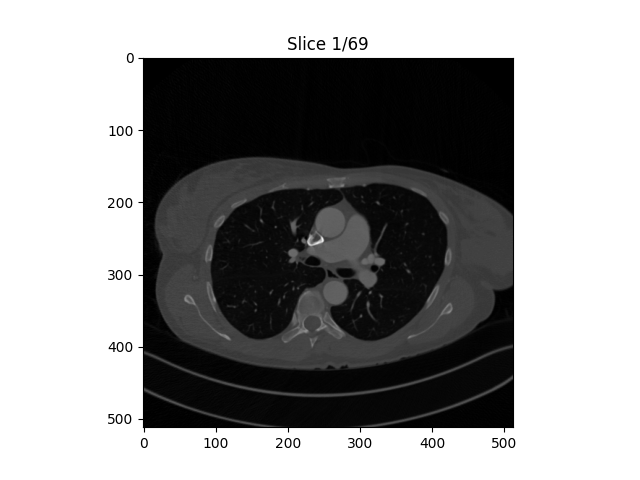

In [26]:
dicom_file_path = 'data/CT CT CARDIAC W WO IV CONTRAST/DICOM/MED RECONS 330 ms/01.dcm'
dicom_data = pydicom.dcmread(dicom_file_path)

print(dicom_data)

plt.imshow(dicom_data.pixel_array, cmap=plt.cm.gray)
plt.show()


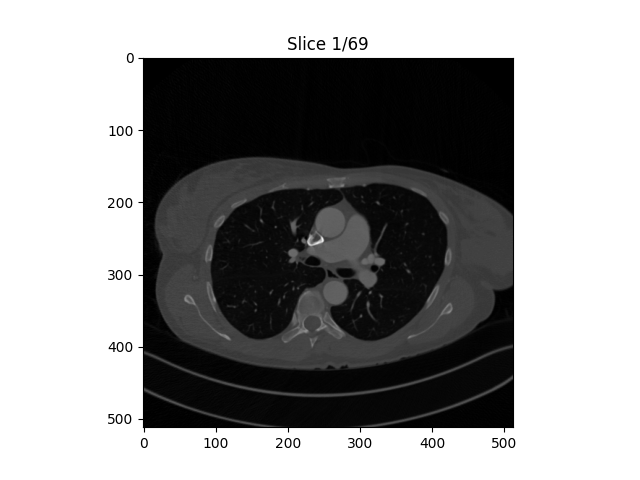

In [27]:
def load_dicom_images(folder_path):
    images = []
    for filename in sorted(os.listdir(folder_path)):
        dicom_file = pydicom.dcmread(f"{folder_path}{filename}")
        images.append(dicom_file.pixel_array)
    return np.array(images)

image_stack = load_dicom_images("data/CT CT CARDIAC W WO IV CONTRAST/DICOM/MED RECONS 330 ms/")

fig, ax = plt.subplots()

current_index = 0
image_displayed = ax.imshow(image_stack[current_index], cmap='grey')
ax.set_title(f"Slice {current_index + 1}/{len(image_stack)}")


def update_image(index):
    global current_index
    current_index = index
    image_displayed.set_data(image_stack[current_index])
    ax.set_title(f"Slice {current_index + 1}/{len(image_stack)}")
    fig.canvas.draw_idle()

def on_key(event):
    global current_index
    if event.key == 'right':
        current_index += 1
        current_index %= len(image_stack)
        update_image(current_index)
    elif event.key == 'left':
        current_index -= 1
        current_index %= len(image_stack)
        update_image(current_index)

fig.canvas.mpl_connect('key_press_event', on_key)

plt.show()

